# 01 – Exploration des données : gravité des accidents corporels (BAAC)
**Objectif** : classer la gravité d'un accident corporel (`grav_max` = gravité de l'usager le plus touché) à partir de ses caractéristiques.
**Source** : data.gouv.fr – BAAC (Licence Ouverte). Année de travail : 2023.
**Une ligne = un accident** (54 822 accidents). Le jeu est construit par `src/build_dataset.py` (`make dataset`) à partir des 4 tables brutes.


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
YEAR = 2023
LOCAL = Path("../data/processed")/f"accidents_{YEAR}.csv"
URL = f"https://raw.githubusercontent.com/cyannure/aaa/main/data/processed/accidents_{YEAR}.csv"

## 1. Chargement
20 features en 4 groupes :
- **Accident** : `heure`, `week_end`, `lum`, `atm`, `agg`, `int`, `col`
- **Lieu** (1re ligne de `lieux` par accident) : `catr`, `vma`, `surf`, `situ`, `nbv`
- **Conducteurs** (agrégés) : `age_cond_max`, `part_cond_hommes`, `part_cond_loisirs`, `part_cond_proteges`
- **Véhicules** (agrégés) : `veh_vulnerable`, `choc_avant`, `manv_risquee`, `pieton_heurte`

Les codes BAAC sont lus comme des nombres mais sont **catégoriels** : on les convertit.

In [2]:
CAT = ["lum","atm","agg","int","col","catr","surf","situ","veh_vulnerable"]
BIN = ["week_end","choc_avant","manv_risquee","pieton_heurte"]
NUM = ["heure","vma","nbv","age_cond_max","part_cond_hommes","part_cond_loisirs","part_cond_proteges"]
TARGET = "grav_max"
df = pd.read_csv(LOCAL if LOCAL.exists() else URL, dtype={c: "string" for c in CAT})
df[CAT] = df[CAT].astype("category")
df[TARGET] = pd.Categorical(df[TARGET], categories=["leger","hospitalise","tue"], ordered=True)
print(df.shape); df.head()

(54822, 21)


,heure,week_end,lum,atm,agg,int,col,catr,surf,situ,vma,nbv,age_cond_max,part_cond_hommes,part_cond_loisirs,part_cond_proteges,veh_vulnerable,choc_avant,manv_risquee,pieton_heurte,grav_max
0,6.0,1,1,2,2,4,7,4,2,1,30.0,2.0,45.0,1.000000,1.0,1.0,2rm_3rm,0,0,0,leger
1,5.0,1,5,3,2,1,6,3,2,1,50.0,3.0,26.0,0.000000,0.0,1.0,vl_vu,1,0,1,hospitalise
2,20.0,1,1,2,2,3,1,3,2,1,50.0,4.0,39.0,0.500000,NaN,1.0,2rm_3rm,1,0,0,hospitalise
3,23.0,1,5,3,2,1,5,2,2,1,50.0,4.0,55.0,0.666667,0.0,1.0,vl_vu,1,0,0,leger
4,0.0,1,5,3,2,2,3,4,2,1,30.0,1.0,22.0,0.500000,0.0,1.0,vl_vu,1,0,0,leger


## 2. Métadonnées, types et valeurs manquantes

In [3]:
info = pd.DataFrame({"type": df.dtypes.astype(str), "nunique": df.nunique(),
                     "na_%": (df.isna().mean()*100).round(1)}).sort_values("na_%", ascending=False)
info

,type,nunique,na_%
part_cond_loisirs,float64,17,21.3
part_cond_proteges,float64,8,10.4
vma,float64,19,3.8
nbv,float64,13,3.3
age_cond_max,float64,96,1.4
part_cond_hommes,float64,20,1.3
veh_vulnerable,category,4,0.3
surf,category,9,0.1
situ,category,7,0.1
pieton_heurte,int64,2,0.0


## 3. Variable cible `grav_max`
Pas de classe « indemne » : un accident corporel a au moins un blessé.

grav_max
leger          0.639
hospitalise    0.302
tue            0.058
Name: proportion, dtype: float64


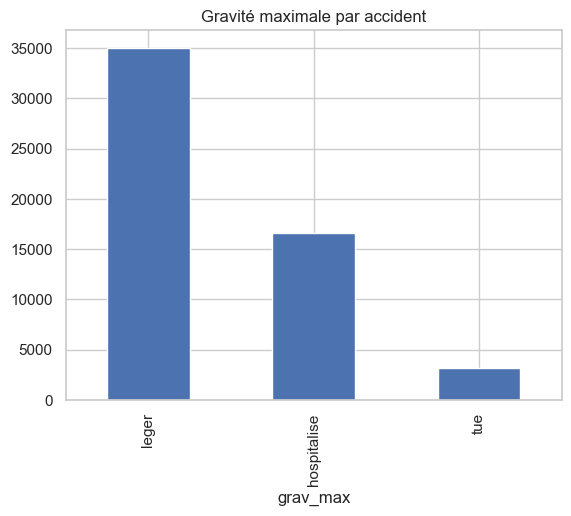

In [4]:
print(df[TARGET].value_counts(normalize=True).round(3))
df[TARGET].value_counts().sort_index().plot.bar(title="Gravité maximale par accident"); plt.show()

## 4. Distributions des variables
Histogrammes pour les 7 numériques, effectifs par modalité pour les 4 binaires et les 9 catégorielles (NaN inclus).

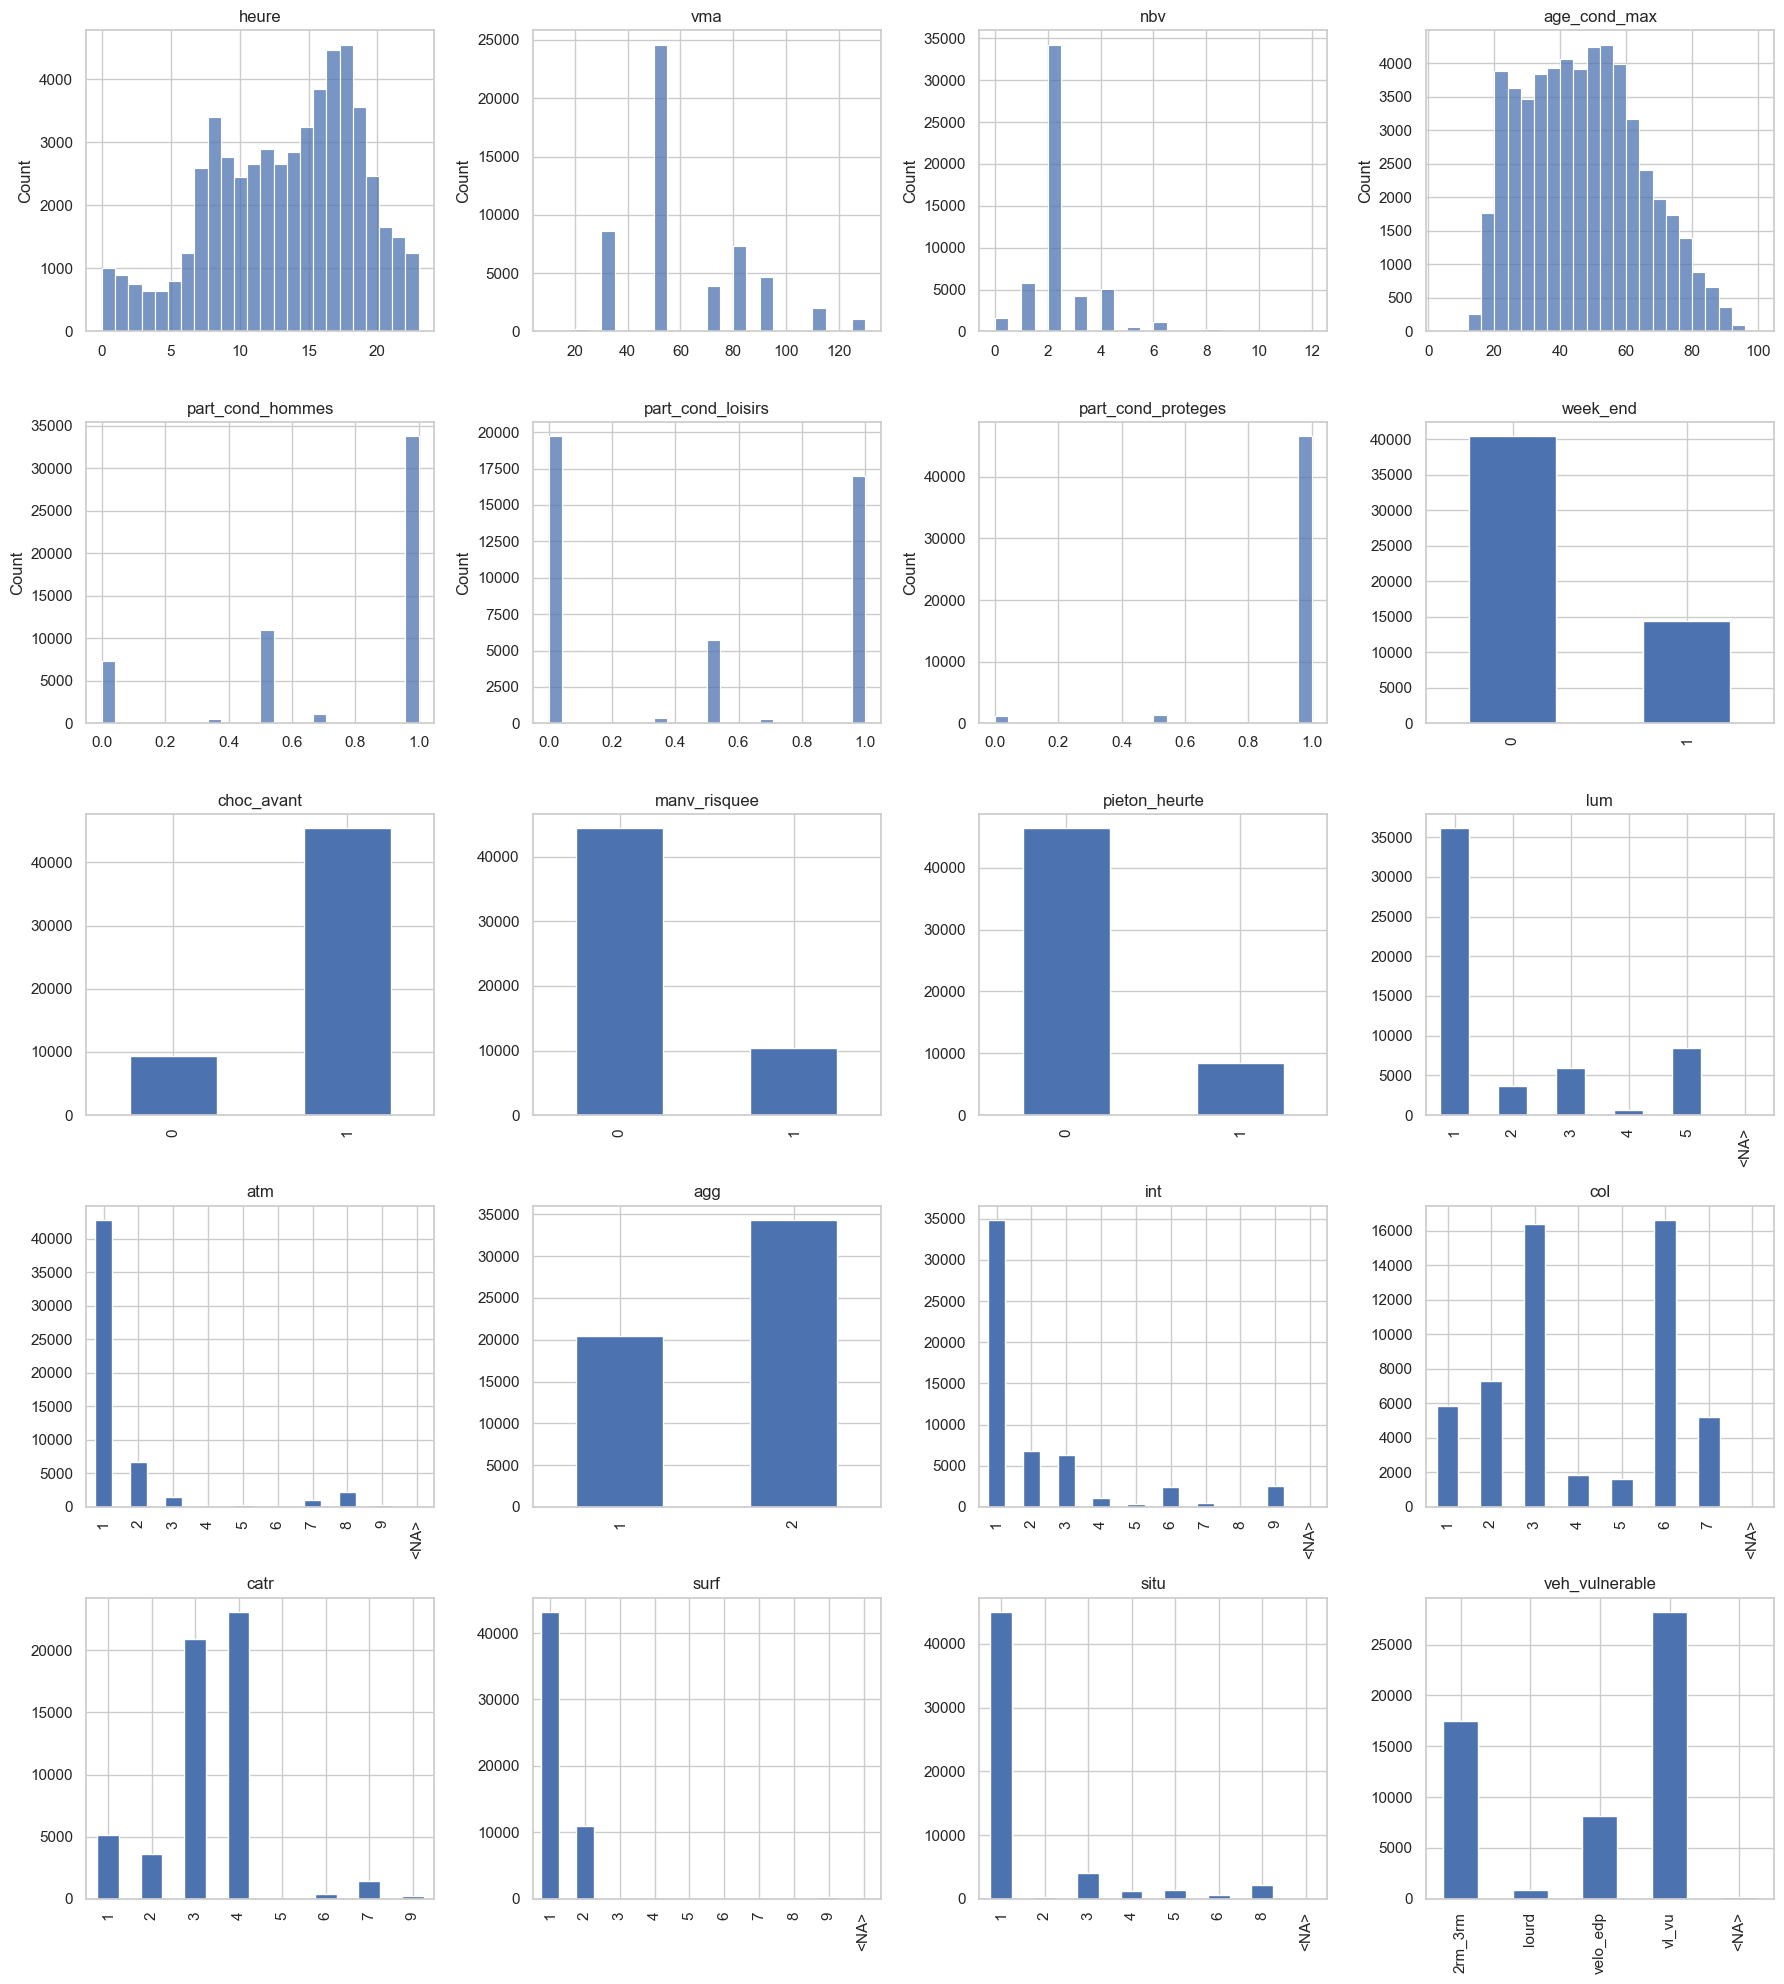

In [5]:
FEATURES = NUM + BIN + CAT
fig, axes = plt.subplots(5, 4, figsize=(18,20))
for a, c in zip(axes.ravel(), FEATURES):
    if c in NUM:
        sns.histplot(df[c].dropna(), bins=24, ax=a)
    else:
        df[c].value_counts(dropna=False).sort_index().plot.bar(ax=a)
    a.set_title(c); a.set_xlabel("")
plt.tight_layout(); plt.show()

### Lien avec la cible
Pour chaque modalité des variables catégorielles et binaires : répartition des classes de `grav_max`.

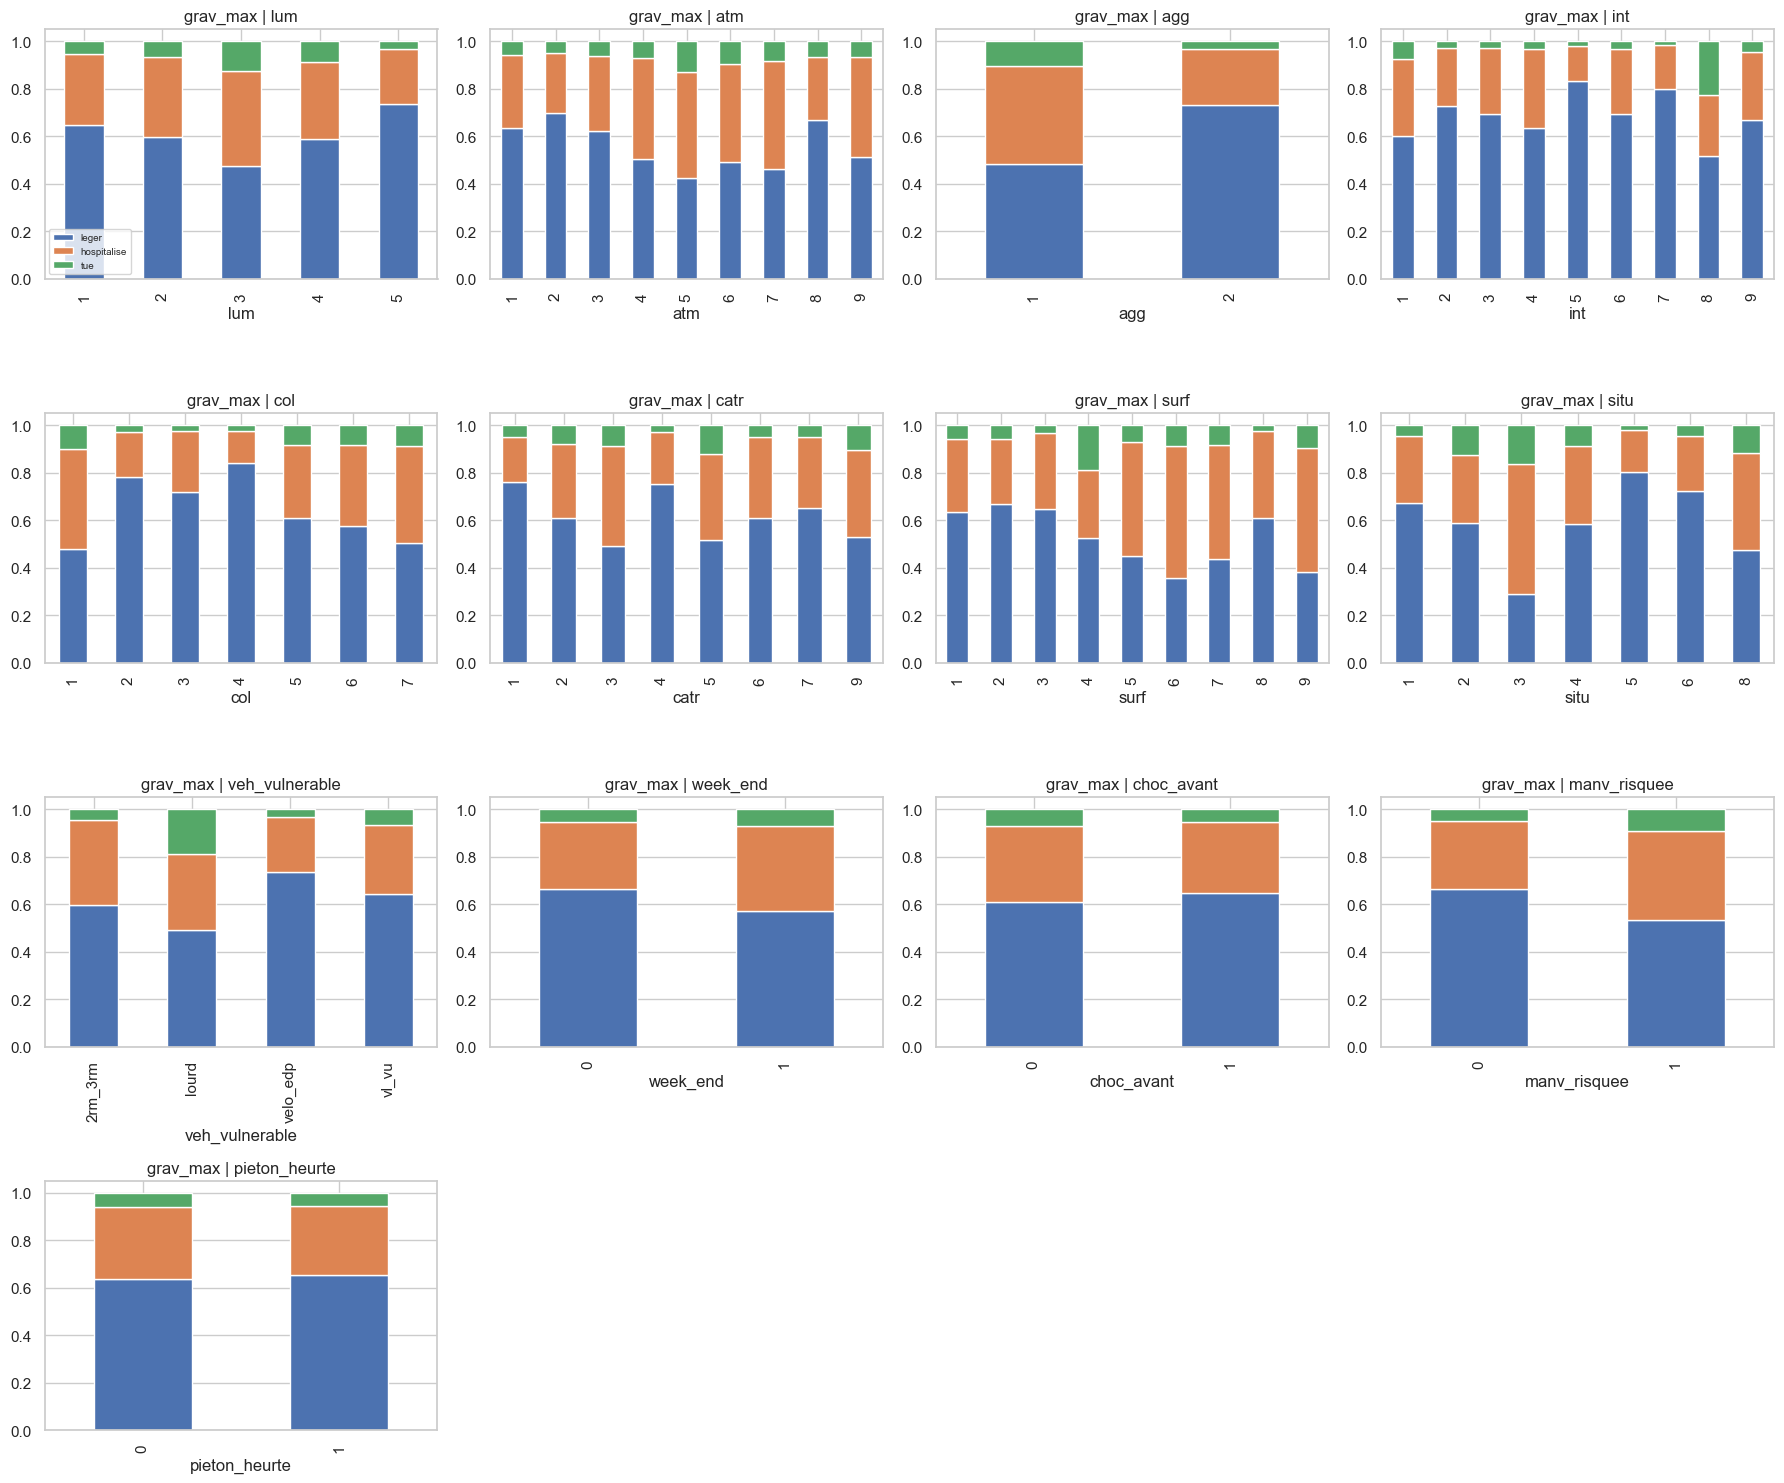

In [6]:
cols = CAT + BIN
fig, axes = plt.subplots(4, 4, figsize=(18,15))
for a, c in zip(axes.ravel(), cols):
    pd.crosstab(df[c], df[TARGET], normalize="index").plot.bar(stacked=True, ax=a, legend=False, title=f"grav_max | {c}")
for a in axes.ravel()[len(cols):]: a.axis("off")
axes[0,0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 5. Corrélations, clustering non supervisé, conclusions
À compléter : matrice de corrélation (Cramér's V pour les catégorielles), PCA/UMAP, K-Means vs `grav_max`, décisions de preprocessing.